# Mushroom Classification — Edible or Poisonous?

**Dataset:** UCI Mushroom — 8,124 mushroom descriptions with 22 physical characteristics (cap shape, odour, gill colour, spore print…) labelled edible or poisonous.

⚠️ **Safety first:** this is a pattern-recognition exercise on a textbook dataset. Never eat a wild mushroom based on any model — real identification needs an expert, and this dataset's 'edible' labels come from a field guide, not a guarantee.

In [1]:
import io, urllib.request, zipfile
import pandas as pd

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

zf = zipfile.ZipFile(io.BytesIO(get('https://archive.ics.uci.edu/static/public/73/mushroom.zip')))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
cols = ['class','cap-shape','cap-surface','cap-color','bruises','odor','gill-attachment','gill-spacing','gill-size','gill-color','stalk-shape','stalk-root','stalk-surface-above-ring','stalk-surface-below-ring','stalk-color-above-ring','stalk-color-below-ring','veil-type','veil-color','ring-number','ring-type','spore-print-color','population','habitat']
d = pd.read_csv(io.BytesIO(zf.read(name)), header=None, names=cols)
print(d.shape)
print('Poisonous share:', round(100 * (d['class'] == 'p').mean(), 1), '%')

(8124, 23)
Poisonous share: 48.2 %


Accuracy: 1.0
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00      1052
   Poisonous       1.00      1.00      1.00       979

    accuracy                           1.00      2031
   macro avg       1.00      1.00      1.00      2031
weighted avg       1.00      1.00      1.00      2031



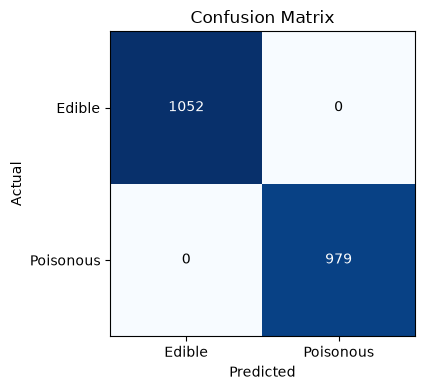

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

y = (d['class'] == 'p').astype(int)  # 1 = poisonous — the class we must never miss
X = pd.get_dummies(d.drop(columns=['class']), drop_first=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(Xtr, ytr)
pred = rf.predict(Xte)
print('Accuracy:', round(accuracy_score(yte, pred), 4))
print(classification_report(yte, pred, target_names=['Edible', 'Poisonous']))
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['Edible', 'Poisonous']); ax.set_yticks([0, 1], ['Edible', 'Poisonous'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- This dataset is (nearly) perfectly separable — odour alone almost decides it. A near-100% score says more about the dataset than the model.
- For safety-flavoured tasks the metric that matters is recall on the dangerous class: a poisonous mushroom called 'edible' is the only unforgivable error.
- Textbook-perfect data is not the real world: species outside this guide are simply absent.